# HD-PROCOVA Results

Visualize cross-validation and final model results from the HBM + ML pipeline on simulated data.

**Prerequisites:** Run these first:
```bash
python scripts/generate_data.py
python scripts/train_cv.py 1        # at least one fold
python scripts/train_final.py       # optional: final model
```

In [9]:
import sys
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_squared_error

PROJECT_ROOT = (Path.cwd() / '..').resolve()
RESULTS_DIR = PROJECT_ROOT / 'outputs' / 'training'
FINAL_DIR = PROJECT_ROOT / 'outputs' / 'final'

plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Load cross-validation results

In [10]:
FOLD_RE = re.compile(r'results_fold_(\d+)\.csv$')
EXCLUDE = {'hbm', 'deployment'}

frames = []
for fp in sorted(RESULTS_DIR.glob('**/results_fold_*.csv')):
    model = fp.parent.name
    if model in EXCLUDE:
        continue
    fold = int(FOLD_RE.search(fp.name).group(1))
    df = pd.read_csv(fp)
    df['model'] = model
    df['fold'] = fold
    frames.append(df)

if frames:
    cv_df = pd.concat(frames, ignore_index=True)
    print(f'Loaded {len(frames)} fold files | {len(cv_df)} rows')
    print(f'Models: {sorted(cv_df["model"].unique())}')
else:
    print('No CV results found. Run: python scripts/train_cv.py 1')
    cv_df = None

Loaded 60 fold files | 26361 rows
Models: ['decision_tree', 'elasticnet', 'histgradientboosting', 'lasso', 'lightgbm', 'random_forest', 'ridge', 'svr', 'xgboost']


## 2. Model performance comparison

In [11]:
if cv_df is not None:
    metrics = []
    for (model, fold), g in cv_df.groupby(['model', 'fold']):
        if len(g) > 1:
            r2 = r2_score(g['actual_change'], g['predicted_change'])
            rmse = np.sqrt(mean_squared_error(g['actual_change'], g['predicted_change']))
            corr = np.corrcoef(g['actual_change'], g['predicted_change'])[0, 1]
            metrics.append({'model': model, 'fold': fold, 'R2': r2, 'RMSE': rmse, 'Corr': corr})

    metrics_df = pd.DataFrame(metrics)
    summary = metrics_df.groupby('model')[['R2', 'RMSE', 'Corr']].agg(['mean', 'std'])
    summary.columns = [f'{m}_{s}' for m, s in summary.columns]
    print(summary.sort_values('R2_mean', ascending=False).to_string())

                       R2_mean    R2_std  RMSE_mean  RMSE_std  Corr_mean  Corr_std
model                                                                             
lasso                 0.069838  0.064267   5.079925  0.604567   0.334753  0.070846
elasticnet            0.067960  0.062795   5.086166  0.612307   0.331232  0.073244
svr                   0.065350  0.078086   5.099253  0.686116   0.317064  0.083625
random_forest         0.028916  0.053325   5.195494  0.647343   0.280715  0.137519
ridge                 0.023470  0.167735   5.196913  0.739729   0.342594  0.092063
xgboost               0.009962  0.114399   5.255728  0.679565   0.240104  0.131862
lightgbm             -0.007733  0.045162   5.315870  0.702144   0.200736  0.074252
histgradientboosting -0.018376  0.114826   5.343529  0.800941   0.222761  0.116799
decision_tree        -0.103286  0.049238   5.534899  0.665287  -0.041969  0.092925


/tmp/ipykernel_2949282/243698595.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/tmp/ipykernel_2949282/243698595.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/tmp/ipykernel_2949282/243698595.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


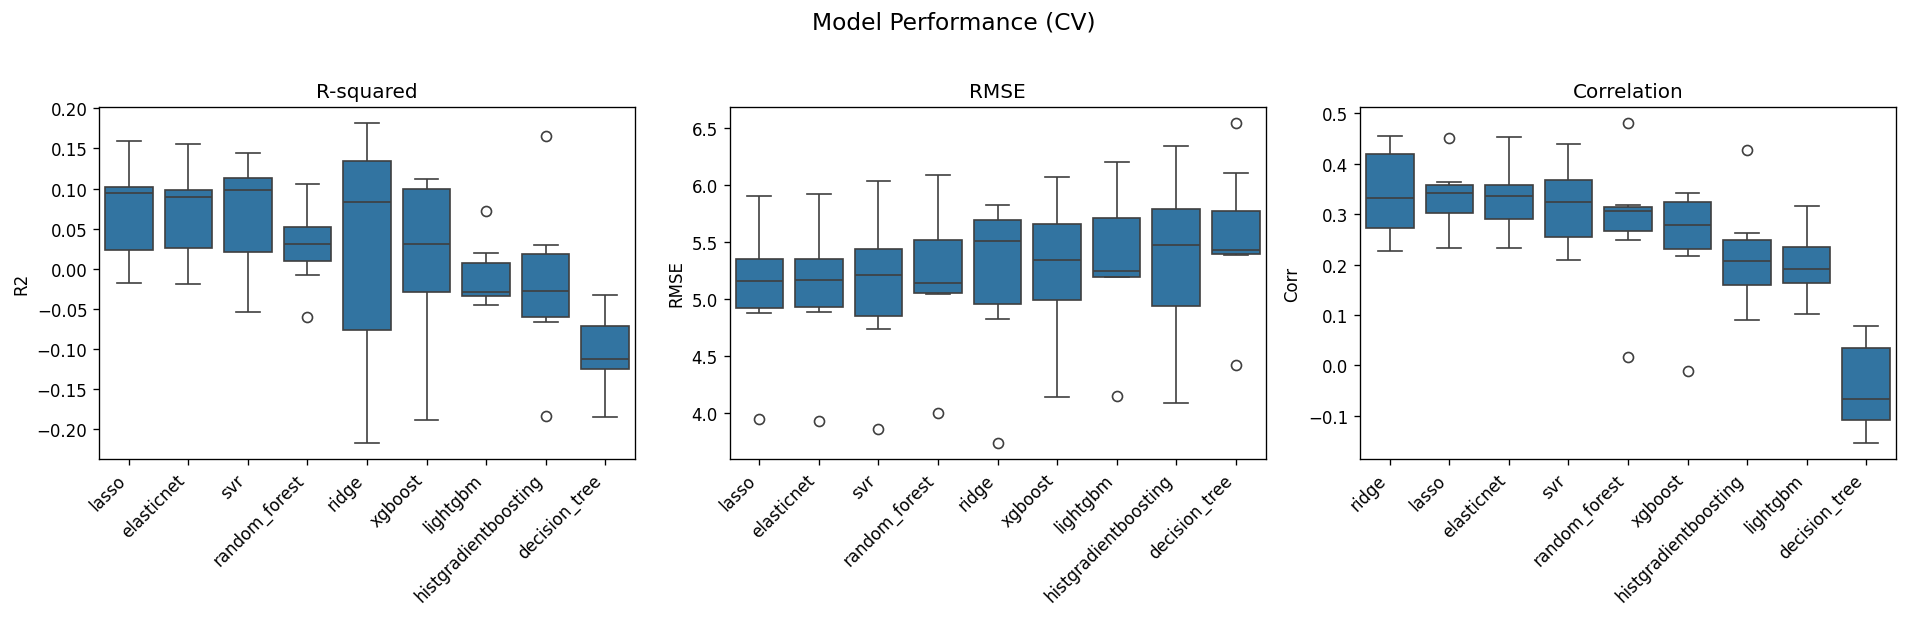

In [12]:
if cv_df is not None and len(metrics_df) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    for ax, metric, label in zip(axes, ['R2', 'RMSE', 'Corr'], ['R-squared', 'RMSE', 'Correlation']):
        order = metrics_df.groupby('model')[metric].mean().sort_values(ascending=(metric == 'RMSE')).index
        sns.boxplot(data=metrics_df, x='model', y=metric, order=order, ax=ax)
        ax.set_title(label)
        ax.set_xlabel('')
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

    fig.suptitle('Model Performance (CV)', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

## 3. Predicted vs actual change

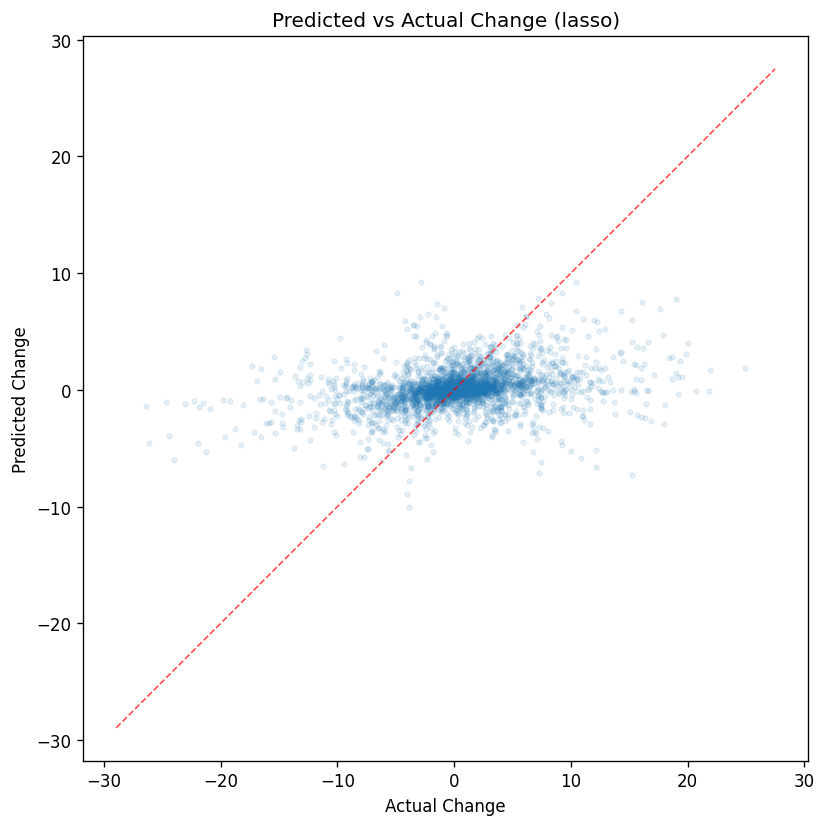

In [13]:
if cv_df is not None:
    best_model = metrics_df.groupby('model')['R2'].mean().idxmax()
    plot_df = cv_df[cv_df['model'] == best_model]

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.scatter(plot_df['actual_change'], plot_df['predicted_change'], alpha=0.1, s=8)
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, 'r--', lw=1, alpha=0.7)
    ax.set_xlabel('Actual Change')
    ax.set_ylabel('Predicted Change')
    ax.set_title(f'Predicted vs Actual Change ({best_model})')
    ax.set_aspect('equal')
    plt.tight_layout()
    plt.show()

## 4. Feature importance

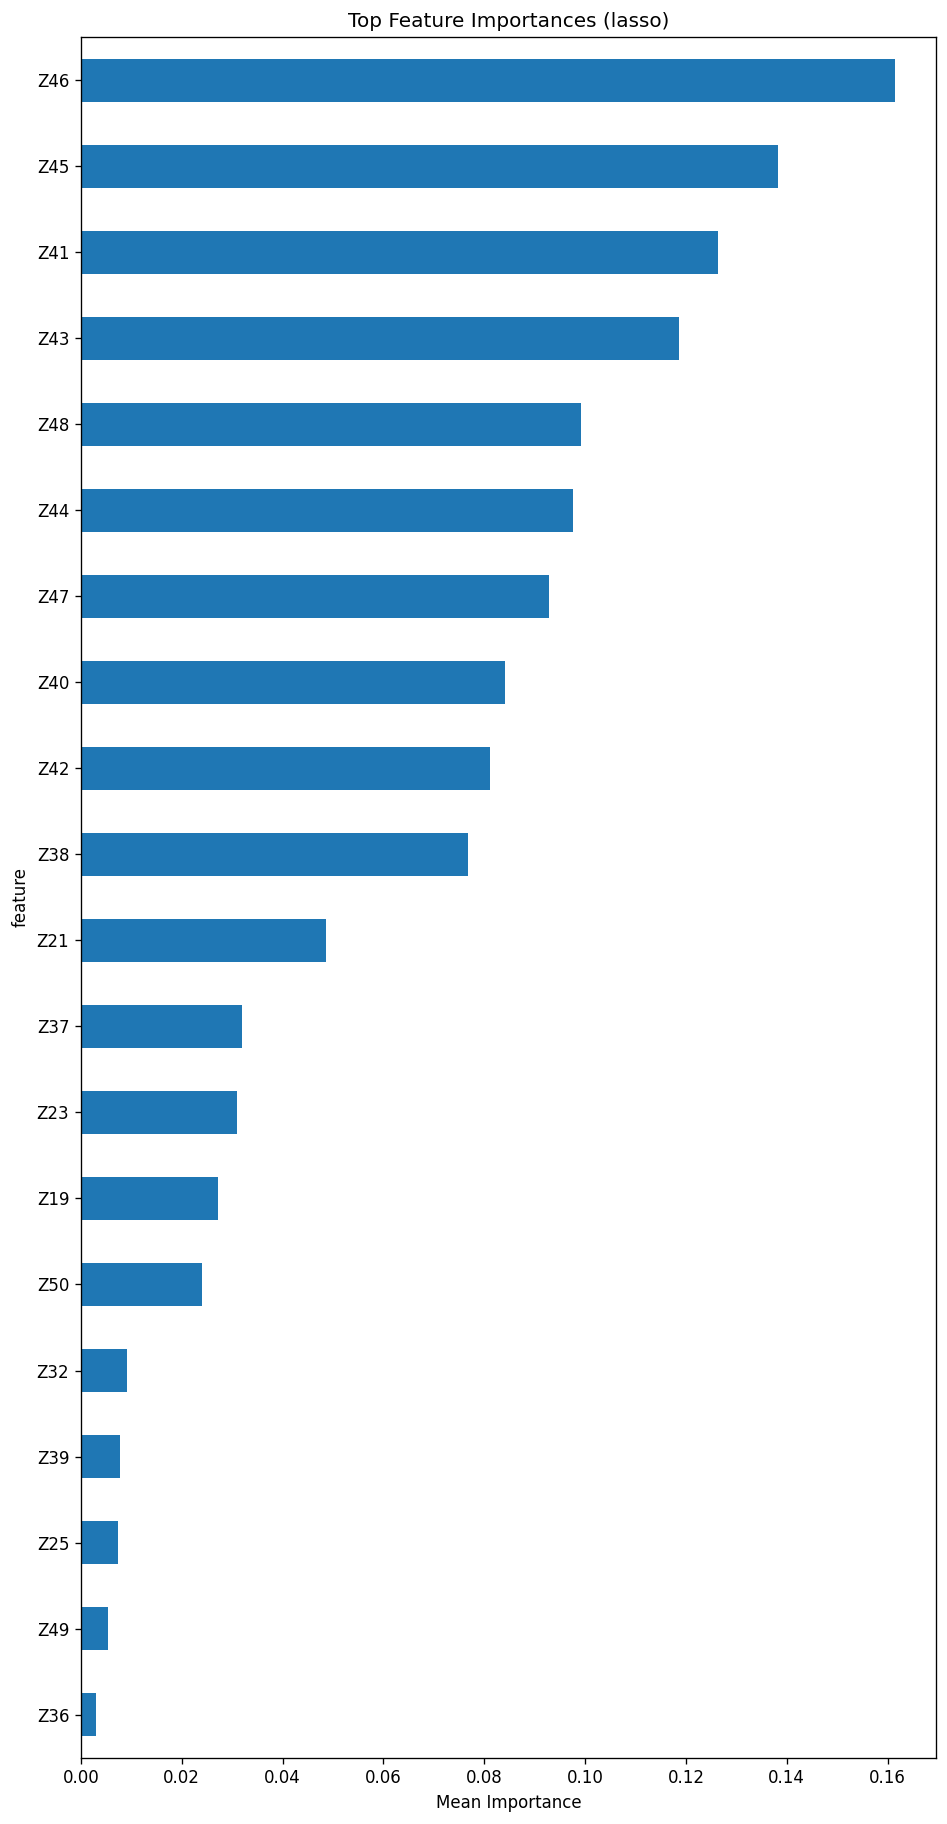

In [14]:
imp_frames = []
for fp in sorted(RESULTS_DIR.glob('**/importance_fold_*.csv')):
    model = fp.parent.name
    if model in EXCLUDE:
        continue
    fold = int(re.search(r'fold_(\d+)', fp.name).group(1))
    tmp = pd.read_csv(fp)
    tmp['model'] = model
    tmp['fold'] = fold
    imp_frames.append(tmp)

if imp_frames:
    imp_df = pd.concat(imp_frames, ignore_index=True)

    # Show mean importance for the best model
    if cv_df is not None:
        best_imp = imp_df[imp_df['model'] == best_model]
        mean_imp = best_imp.groupby('feature')['importance_mean'].mean().sort_values()

        fig, ax = plt.subplots(figsize=(8, max(4, len(mean_imp) * 0.3)))
        mean_imp.tail(20).plot.barh(ax=ax)
        ax.set_title(f'Top Feature Importances ({best_model})')
        ax.set_xlabel('Mean Importance')
        plt.tight_layout()
        plt.show()
else:
    print('No importance files found.')

## 5. Final model results

In [15]:
final_frames = []
if FINAL_DIR.exists():
    for fp in sorted(FINAL_DIR.glob('*/predictions.csv')):
        model = fp.parent.name
        if model in EXCLUDE:
            continue
        tmp = pd.read_csv(fp)
        tmp['model'] = model
        final_frames.append(tmp)

if final_frames:
    final_df = pd.concat(final_frames, ignore_index=True)
    print(f'Loaded {len(final_frames)} final model predictions')

    final_metrics = []
    for model, g in final_df.groupby('model'):
        if 'actual_change' in g.columns and len(g) > 1:
            r2 = r2_score(g['actual_change'], g['predicted_change'])
            rmse = np.sqrt(mean_squared_error(g['actual_change'], g['predicted_change']))
            corr = np.corrcoef(g['actual_change'], g['predicted_change'])[0, 1]
            final_metrics.append({'model': model, 'R2': r2, 'RMSE': rmse, 'Corr': corr})

    if final_metrics:
        fm_df = pd.DataFrame(final_metrics).set_index('model').sort_values('R2', ascending=False)
        print(fm_df.to_string())
else:
    print('No final model results. Run: python scripts/train_final.py')

No final model results. Run: python scripts/train_final.py
